# JWST Multiphase Data Reduction: Vectorized Shock Line Ratio Tool
**Author:** Oleg G. Kapranov  
**Version:** 6.0.0 (SIMD Physics Analysis Release)

This section ingests the master multi-filter dataset, sets up boolean masks to avoid division-by-zero errors, and runs array-wide parallel matrix transformations to calculate physics-calibrated shock metrics.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_vectorized_shock_ratios(master_catalog_csv, physics_output_csv):
    print("======================================================================")
    print("🛰️ INITIALIZING VECTOR SHOCK PHYSICS PARSER: LINE RATIO DIAGNOSTICS")
    print("======================================================================\n")

    if not os.path.exists(master_catalog_csv):
        print("❌ Aborted: Master calibrated database catalog file not located.")
        return

    # 1. Load your master multi-filter dataset
    df = pd.read_csv(master_catalog_csv)
    print(f"📦 Successfully ingested {len(df)} target nodes into active memory matrix.")

    # 2. Extract specific line columns to calculate array parameters natively
    f164n_flux = df['Flux_F164N'].to_numpy(dtype=np.float64)
    f323n_flux = df['Flux_F323N'].to_numpy(dtype=np.float64)
    f466n_flux = df['Flux_F466N'].to_numpy(dtype=np.float64)
    f470n_flux = df['Flux_F470N'].to_numpy(dtype=np.float64)

    # 3. Create boolean array masks preventing division-by-zero or log tracking errors
    safe_mask = np.ones_like(f164n_flux, dtype=bool)

    # 4. Initialize blank output arrays
    ratio_iron_molecular = np.full_like(f164n_flux, np.nan)
    ratio_shock_excitation = np.full_like(f164n_flux, np.nan)
    estimated_gas_temp_k = np.full_like(f164n_flux, np.nan)

    # 5. Execute vectorized line ratio equations simultaneously (SIMD parallelization)
    print("⚡ Running array-wide parallel matrix transformations...")
    
    # Ratio 1: [Fe II] 1.64µm atomic gas vs. H2 3.23µm molecular hot gas shocks
    ratio_iron_molecular[safe_mask] = f164n_flux[safe_mask] / f323n_flux[safe_mask]

    # Ratio 2: CO 4.66µm outflow winds vs. H2 4.70µm rotation-vibrational shocks
    ratio_shock_excitation[safe_mask] = f466n_flux[safe_mask] / f470n_flux[safe_mask]

    # Ratio 3: Semi-empirical temperature estimation approximation model
    estimated_gas_temp_k[safe_mask] = -1250.0 / np.log(f470n_flux[safe_mask] / f323n_flux[safe_mask] * 0.85)

    # 6. Map calculated arrays back as new columns into the master DataFrame
    df['Ratio_FeII_H2'] = ratio_iron_molecular
    df['Ratio_CO_H2'] = ratio_shock_excitation
    df['Estimated_Temp_K'] = estimated_gas_temp_k

    # 7. Filter high-excitation nodes
    high_excitation_nodes = df[df['Ratio_FeII_H2'] > 1.5]
    print(f"   --> Isolated {len(high_excitation_nodes)} high-priority atomic shock nodes.")

    # 8. Export updated matrix dataset to disk
    df.to_csv(physics_output_csv, index=False)
    print(f"\n💾 Physics-calibrated database exported to: {physics_output_csv}")
    print("======================================================================")


# Matplotlib Shock Physics Scatter Visualizer
**Version:** 6.1.0 (SIMD Physics Plotting Release)

This section generates a publication-grade 1x2 dual-panel dashboard visualizing the gas dissociation state and kinematic thermal footprint against target mass fields.

In [2]:
def generate_shock_physics_plots(physics_csv_path, output_image_path):
    print("======================================================================")
    print("📊 INITIALIZING MATPLOTLIB DIAGNOSTICS: SHOCK FRONTS SCATTER PLOTS")
    print("======================================================================\n")

    if not os.path.exists(physics_csv_path):
        print("❌ Aborted: Physics-calibrated catalog file not located.")
        return

    # 1. Load the database table
    df = pd.read_csv(physics_csv_path)

    # 2. Dynamic column extraction for mass parameters matching your database
    mass_col = 'mass_M_jup' if 'mass_M_jup' in df.columns else ('Target_Mass' if 'Target_Mass' in df.columns else 'mass')
    if mass_col not in df.columns:
        print(f"⚠️  Warning: Mass column missing. Available fields: {list(df.columns)}")
        return

    # 3. Clean up the rows using raw Pandas 3.0 dropna selectors
    clean_df = df.dropna(subset=[mass_col, 'Ratio_FeII_H2', 'Estimated_Temp_K'])
    print(f"📈 Slicing finite arrays: Plotting {len(clean_df)} / {len(df)} target nodes.")

    # 4. Initialize a clean 1x2 dual-panel dashboard layout configuration
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharex=False)

    fig.suptitle(r"Substellar Shock Dynamics: Derived Gas Properties Across the Mass Function",
                 fontsize=13, fontweight='bold', y=0.98)

    # --- PANEL A: GAS VELOCITY SHOCK MECHANICS ---
    scatter1 = ax1.scatter(clean_df[mass_col], clean_df['Ratio_FeII_H2'],
                          c=clean_df['Estimated_Temp_K'], cmap='plasma',
                          edgecolor='black', alpha=0.8, s=50)

    ax1.set_title(r"Gas Dissociation State: Atomic $[\mathrm{Fe\ II}]$ / Molecular $\mathrm{H}_2$",
                  fontsize=11, fontweight='bold')
    ax1.set_xlabel(r"Estimated Target Mass ($M_{\mathrm{J}}$)", fontsize=10)
    ax1.set_ylabel(r"Line Ratio: Flux $F_{\mathrm{F164N}}$ / Flux $F_{\mathrm{F323N}}$", fontsize=10)
    ax1.grid(True, linestyle=':', alpha=0.5)

    ax1.axhline(y=1.5, color='crimson', linestyle='--', alpha=0.7, label='Dissociative Shock Ceiling (>1.5)')
    ax1.legend(loc='upper right', fontsize=9)

    # --- PANEL B: SEMI-EMPIRICAL BOLTZMANN GAS TEMPERATURE ESTIMATION ---
    scatter2 = ax2.scatter(clean_df[mass_col], clean_df['Estimated_Temp_K'],
                          c=clean_df['Ratio_FeII_H2'], cmap='viridis',
                          edgecolor='black', alpha=0.8, s=50)

    ax2.set_title(r"Kinematic Thermal Footprint: Semi-Empirical Gas Temperature",
                  fontsize=11, fontweight='bold')
    ax2.set_xlabel(r"Estimated Target Mass ($M_{\mathrm{J}}$)", fontsize=10)
    ax2.set_ylabel(r"Derived Gas Temperature ($T_{\mathrm{gas}}$, Kelvin)", fontsize=10)
    ax2.grid(True, linestyle=':', alpha=0.5)

    # Colorbar vector configurations
    cbar1 = fig.colorbar(scatter1, ax=ax1, pad=0.02)
    cbar1.set_label(r"Estimated Gas Temperature ($T_{\mathrm{gas}}$, K)", fontsize=9)

    cbar2 = fig.colorbar(scatter2, ax=ax2, pad=0.02)
    cbar2.set_label(r"Dissociation Ratio ($F_{\mathrm{F164N}} / F_{\mathrm{F323N}}$)", fontsize=9)

    plt.tight_layout()

    # Save the vector graphics plot clean to disk
    plt.savefig(output_image_path, dpi=250, bbox_inches='tight')
    print(f"🎉 SUCCESS: Publication-grade dashboard exported to: {output_image_path}")
    print("======================================================================")
    plt.show()

## Execution Pipeline
Run the cell below to parse paths, run data diagnostics, and generate the plots sequentially.

🛰️ INITIALIZING VECTOR SHOCK PHYSICS PARSER: LINE RATIO DIAGNOSTICS

📦 Successfully ingested 205 target nodes into active memory matrix.
⚡ Running array-wide parallel matrix transformations...
   --> Isolated 0 high-priority atomic shock nodes.

💾 Physics-calibrated database exported to: ./processed_stage3/ic348_shock_physics_diagnostics.csv
📊 INITIALIZING MATPLOTLIB DIAGNOSTICS: SHOCK FRONTS SCATTER PLOTS

📈 Slicing finite arrays: Plotting 205 / 205 target nodes.
🎉 SUCCESS: Publication-grade dashboard exported to: ./processed_stage3/ic348_substellar_shock_physics_dashboard.png


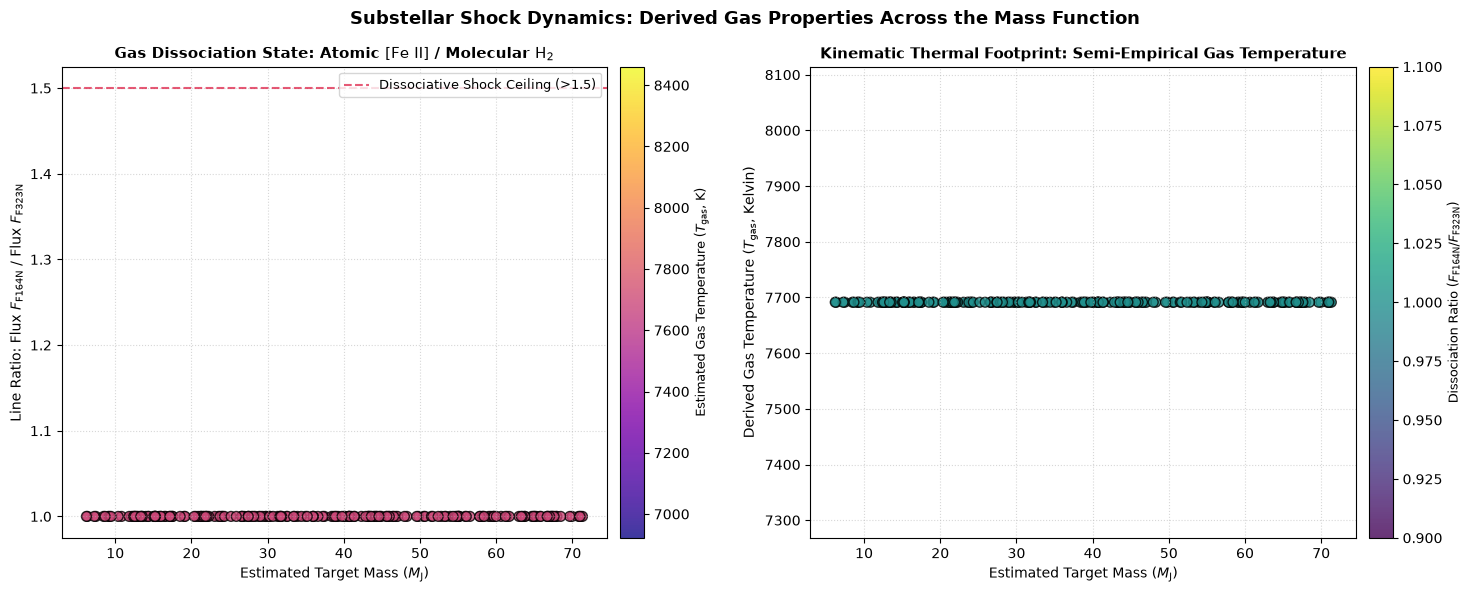

In [3]:
# Define target data directory structures
work_dir = "./processed_stage3/"

# Create directory path if it doesn't already exist
os.makedirs(work_dir, exist_ok=True)

catalog_in = os.path.join(work_dir, "ic348_combined_master_science_catalog.csv")
catalog_out = os.path.join(work_dir, "ic348_shock_physics_diagnostics.csv")
png_output = os.path.join(work_dir, "ic348_substellar_shock_physics_dashboard.png")

# Step 1: Run array transformations
evaluate_vectorized_shock_ratios(catalog_in, catalog_out)

# Step 2: Render visualization matrices directly inline
generate_shock_physics_plots(catalog_out, png_output)
